In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

In [2]:
df = pd.read_csv("strawberry_v1.csv")
df

,berat,panjang,diameter,kadar_gula,kekerasan,varietas,asal_kota,tingkat_kematangan,warna_kulit,grade_kualitas
0,24.5,5.3,3.9,9.8,NaN,Albion,Batu,Mentah,Merah Muda,Afkir
1,26.8,6.3,4.0,10.9,1.28,California,Lembang,Matang,Merah,Premium
2,26.3,5.6,4.1,11.6,0.70,Albion,NaN,Matang,Merah,Premium
3,24.0,5.7,3.8,5.8,1.76,California,Bedugul,Mentah,Hijau Putih,Afkir
4,27.4,5.4,4.0,8.2,1.12,Rosalinda,Bedugul,Mengkal,Merah,Standar
...,...,...,...,...,...,...,...,...,...,...
495,24.4,5.7,3.6,10.7,0.56,Albion,Bedugul,Terlalu Matang,Merah,Standar
496,18.6,4.8,3.0,8.6,1.56,Sweet Charlie,Bedugul,Mengkal,Merah Muda,Standar
497,15.5,4.0,3.3,8.5,1.11,Rosalinda,Batu,Matang,Merah Tua,NaN
498,20.5,4.7,3.0,11.2,0.97,Rosalinda,Batu,Matang,Merah Tua,Premium


In [3]:
df.shape

(500, 10)

In [4]:
df.columns

Index(['berat', 'panjang', 'diameter', 'kadar_gula', 'kekerasan', 'varietas',
       'asal_kota', 'tingkat_kematangan', 'warna_kulit', 'grade_kualitas'],
      dtype='str')

In [5]:
df.head(10)

,berat,panjang,diameter,kadar_gula,kekerasan,varietas,asal_kota,tingkat_kematangan,warna_kulit,grade_kualitas
0,24.5,5.3,3.9,9.8,NaN,Albion,Batu,Mentah,Merah Muda,Afkir
1,26.8,6.3,4.0,10.9,1.28,California,Lembang,Matang,Merah,Premium
2,26.3,5.6,4.1,11.6,0.70,Albion,NaN,Matang,Merah,Premium
3,24.0,5.7,3.8,5.8,1.76,California,Bedugul,Mentah,Hijau Putih,Afkir
4,27.4,5.4,4.0,8.2,1.12,Rosalinda,Bedugul,Mengkal,Merah,Standar
5,11.0,4.0,2.4,7.9,0.44,Rosalinda,Batu,Terlalu Matang,Merah Tua,Afkir
6,9.6,3.0,2.7,8.0,1.51,Sweet Charlie,Lembang,Mentah,Hijau Putih,Afkir
7,8.0,3.3,2.2,5.2,1.67,Rosalinda,Ciwidey,Mentah,Hijau Putih,Afkir
8,23.5,5.0,3.5,8.0,0.62,Rosalinda,Batu,Terlalu Matang,Merah Tua,Standar
9,8.1,2.5,2.7,10.3,1.11,California,Ciwidey,Matang,Merah Tua,Standar


In [6]:
df.tail(10)

,berat,panjang,diameter,kadar_gula,kekerasan,varietas,asal_kota,tingkat_kematangan,warna_kulit,grade_kualitas
490,15.5,4.7,2.8,11.4,0.75,Sweet Charlie,Lembang,Terlalu Matang,Merah Tua,Standar
491,18.7,4.4,3.3,9.4,0.78,California,Ciwidey,Matang,Merah,Premium
492,11.1,3.8,2.5,10.9,NaN,Sweet Charlie,Ciwidey,Matang,Merah Tua,Standar
493,12.9,3.5,2.6,6.7,NaN,Rosalinda,Bedugul,Terlalu Matang,Merah Tua,Afkir
494,18.7,4.1,3.0,7.5,1.19,Albion,Ciwidey,Mengkal,Merah Muda,Afkir
495,24.4,5.7,3.6,10.7,0.56,Albion,Bedugul,Terlalu Matang,Merah,Standar
496,18.6,4.8,3.0,8.6,1.56,Sweet Charlie,Bedugul,Mengkal,Merah Muda,Standar
497,15.5,4.0,3.3,8.5,1.11,Rosalinda,Batu,Matang,Merah Tua,NaN
498,20.5,4.7,3.0,11.2,0.97,Rosalinda,Batu,Matang,Merah Tua,Premium
499,29.1,6.2,4.3,10.0,NaN,California,Lembang,Matang,Merah,Premium


In [7]:
df.sample(10, random_state=42)

,berat,panjang,diameter,kadar_gula,kekerasan,varietas,asal_kota,tingkat_kematangan,warna_kulit,grade_kualitas
361,17.4,4.4,3.2,11.4,0.96,Albion,Lembang,Matang,Merah,Premium
73,17.9,4.9,3.0,3.8,1.61,Albion,Lembang,Mentah,Hijau Putih,Afkir
374,16.0,4.3,3.2,7.4,1.65,California,Ciwidey,Mengkal,Merah Muda,Standar
155,9.6,3.4,2.0,8.1,0.89,Rosalinda,Batu,Matang,Merah Tua,Standar
104,16.9,4.2,2.9,11.7,0.54,Albion,Ciwidey,Matang,Merah,Premium
394,26.8,5.2,4.2,12.0,0.87,Albion,Lembang,Terlalu Matang,Merah Tua,Standar
377,14.0,3.8,2.8,8.7,1.44,Rosalinda,Ciwidey,Mengkal,Merah,Standar
124,11.0,3.1,2.1,7.3,1.04,Sweet Charlie,Ciwidey,Mengkal,Merah Muda,Afkir
68,20.5,4.7,3.5,8.0,0.77,Rosalinda,Bedugul,Terlalu Matang,Merah Tua,Standar
450,12.7,4.4,2.8,7.7,1.09,Rosalinda,Lembang,Matang,Merah,Standar


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   berat               500 non-null    float64
 1   panjang             500 non-null    float64
 2   diameter            480 non-null    float64
 3   kadar_gula          470 non-null    float64
 4   kekerasan           460 non-null    float64
 5   varietas            500 non-null    str    
 6   asal_kota           475 non-null    str    
 7   tingkat_kematangan  500 non-null    str    
 8   warna_kulit         485 non-null    str    
 9   grade_kualitas      491 non-null    str    
dtypes: float64(5), str(5)
memory usage: 57.4 KB


In [9]:
df.describe()

,berat,panjang,diameter,kadar_gula,kekerasan
count,500.000000,500.000000,480.000000,470.000000,460.000000
mean,19.356800,4.630800,3.329167,8.899787,1.180000
std,5.386576,0.748018,0.568835,2.074081,0.368605
min,8.000000,2.500000,1.800000,3.800000,0.350000
25%,15.775000,4.100000,2.900000,7.525000,0.950000
50%,19.350000,4.600000,3.300000,9.000000,1.185000
75%,22.900000,5.100000,3.700000,10.500000,1.432500
max,33.500000,7.000000,4.800000,13.500000,2.000000


In [10]:
df[["berat", "panjang", "diameter", "kadar_gula", "kekerasan"]].skew()

berat         0.035239
panjang       0.120466
diameter     -0.058973
kadar_gula   -0.213564
kekerasan    -0.109409
dtype: float64

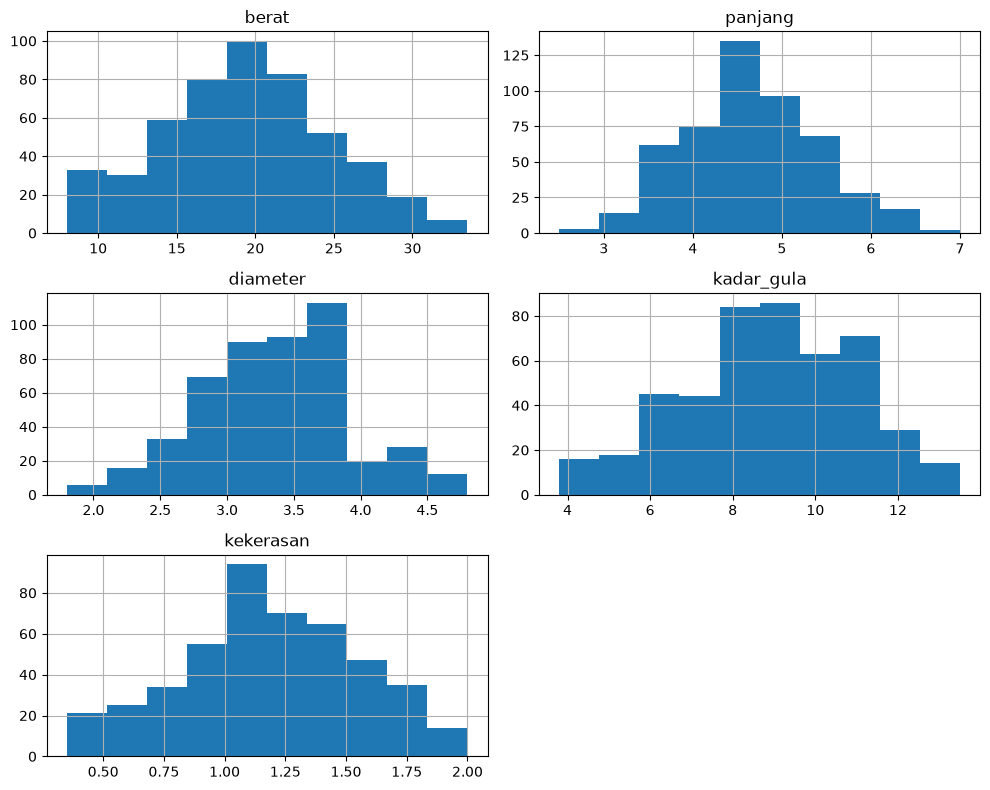

In [11]:
df.hist(figsize=(10, 8))
plt.tight_layout()
plt.show()

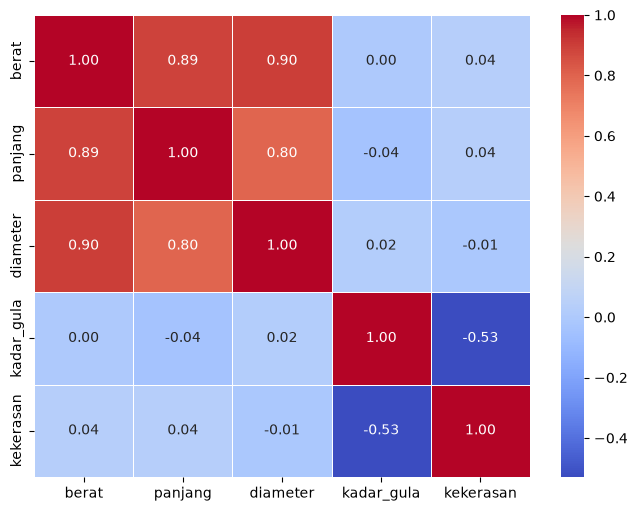

In [12]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.show()

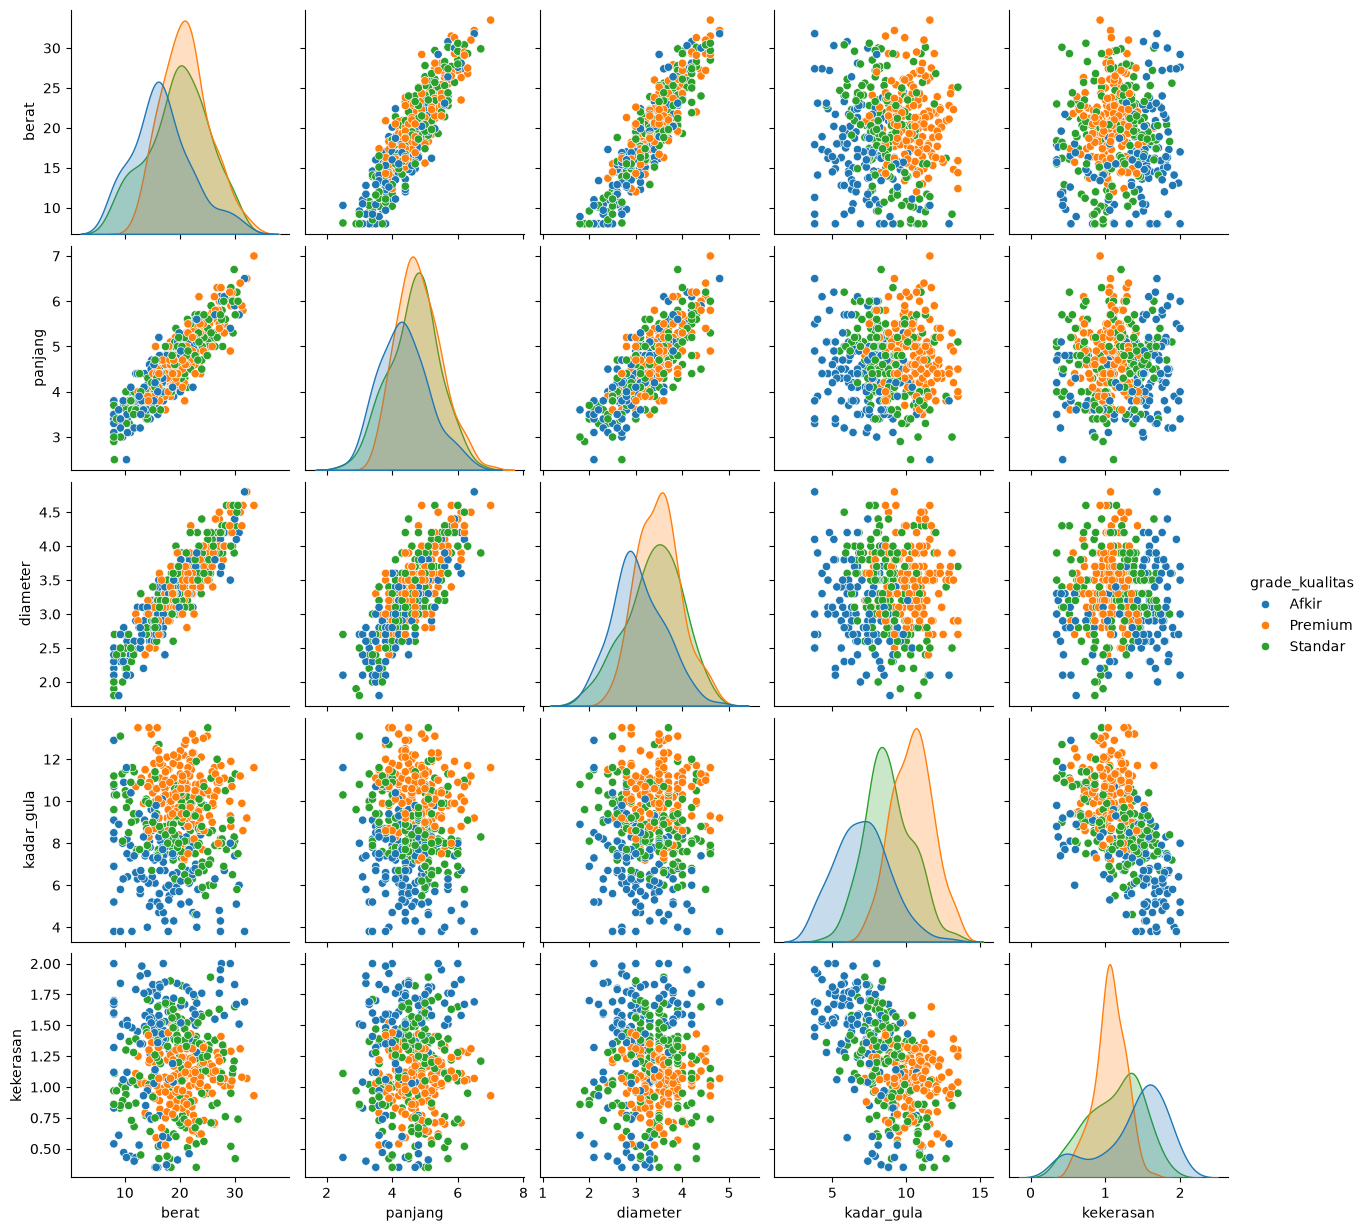

In [13]:
import seaborn as sns

sns.pairplot(df, hue="grade_kualitas")
plt.show()

1. Hubungan Antara Fitur Fisik (berat, panjang, diameter)
   Korelasi Positif Sangat Kuat: Pada scatter plot antara berat vs panjang, berat vs diameter, dan panjang vs diameter, pola titik-titik membentuk garis miring naik ke kanan
   Artinya: Semakin besar ukuran fisik strawberry (panjang/diameter), maka bobot/beratnya dipastikan akan semakin bertambah secara linier

In [14]:
df["varietas"].value_counts()

varietas
Sweet Charlie    142
Albion           140
California       122
Rosalinda         96
Name: count, dtype: int64

In [15]:
df["asal_kota"].value_counts()

asal_kota
Lembang    138
Batu       126
Ciwidey    113
Bedugul     98
Name: count, dtype: int64

In [16]:
df["tingkat_kematangan"].value_counts()

tingkat_kematangan
Matang            213
Mengkal           140
Mentah             78
Terlalu Matang     69
Name: count, dtype: int64

In [17]:
df["warna_kulit"].value_counts()

warna_kulit
Merah          180
Merah Tua      123
Merah Muda     119
Hijau Putih     63
Name: count, dtype: int64

In [18]:
df["grade_kualitas"].value_counts()

grade_kualitas
Premium    177
Standar    174
Afkir      140
Name: count, dtype: int64

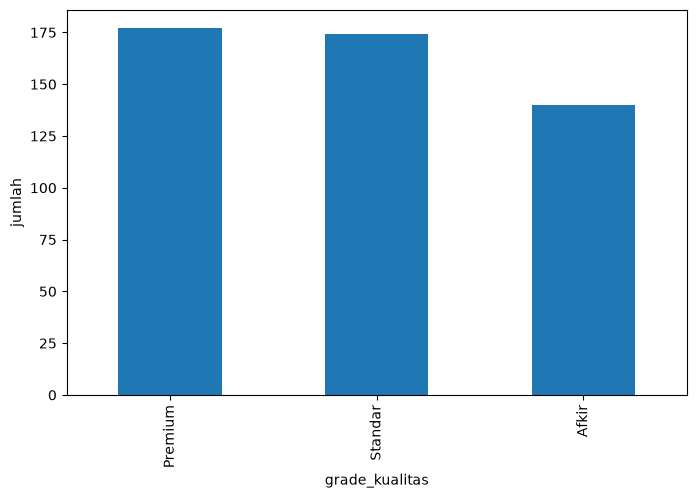

In [19]:
df["grade_kualitas"].value_counts().plot(kind="bar", figsize=(8, 5))
plt.xlabel("grade_kualitas")
plt.ylabel("jumlah")
plt.show()

In [20]:
df.isnull().sum()

berat                  0
panjang                0
diameter              20
kadar_gula            30
kekerasan             40
varietas               0
asal_kota             25
tingkat_kematangan     0
warna_kulit           15
grade_kualitas         9
dtype: int64

In [21]:
df = df.dropna(subset=["grade_kualitas"]).copy()
for col in ["berat", "panjang", "diameter", "kadar_gula", "kekerasan"]:
    if abs(df[col].skew()) < 0.5:
        df[col] = df[col].fillna(df[col].mean())
    else:
        df[col] = df[col].fillna(df[col].median())
for col in ["varietas", "asal_kota", "tingkat_kematangan", "warna_kulit"]:
    df[col] = df[col].fillna(df[col].mode()[0])
df.isnull().sum()

berat                 0
panjang               0
diameter              0
kadar_gula            0
kekerasan             0
varietas              0
asal_kota             0
tingkat_kematangan    0
warna_kulit           0
grade_kualitas        0
dtype: int64

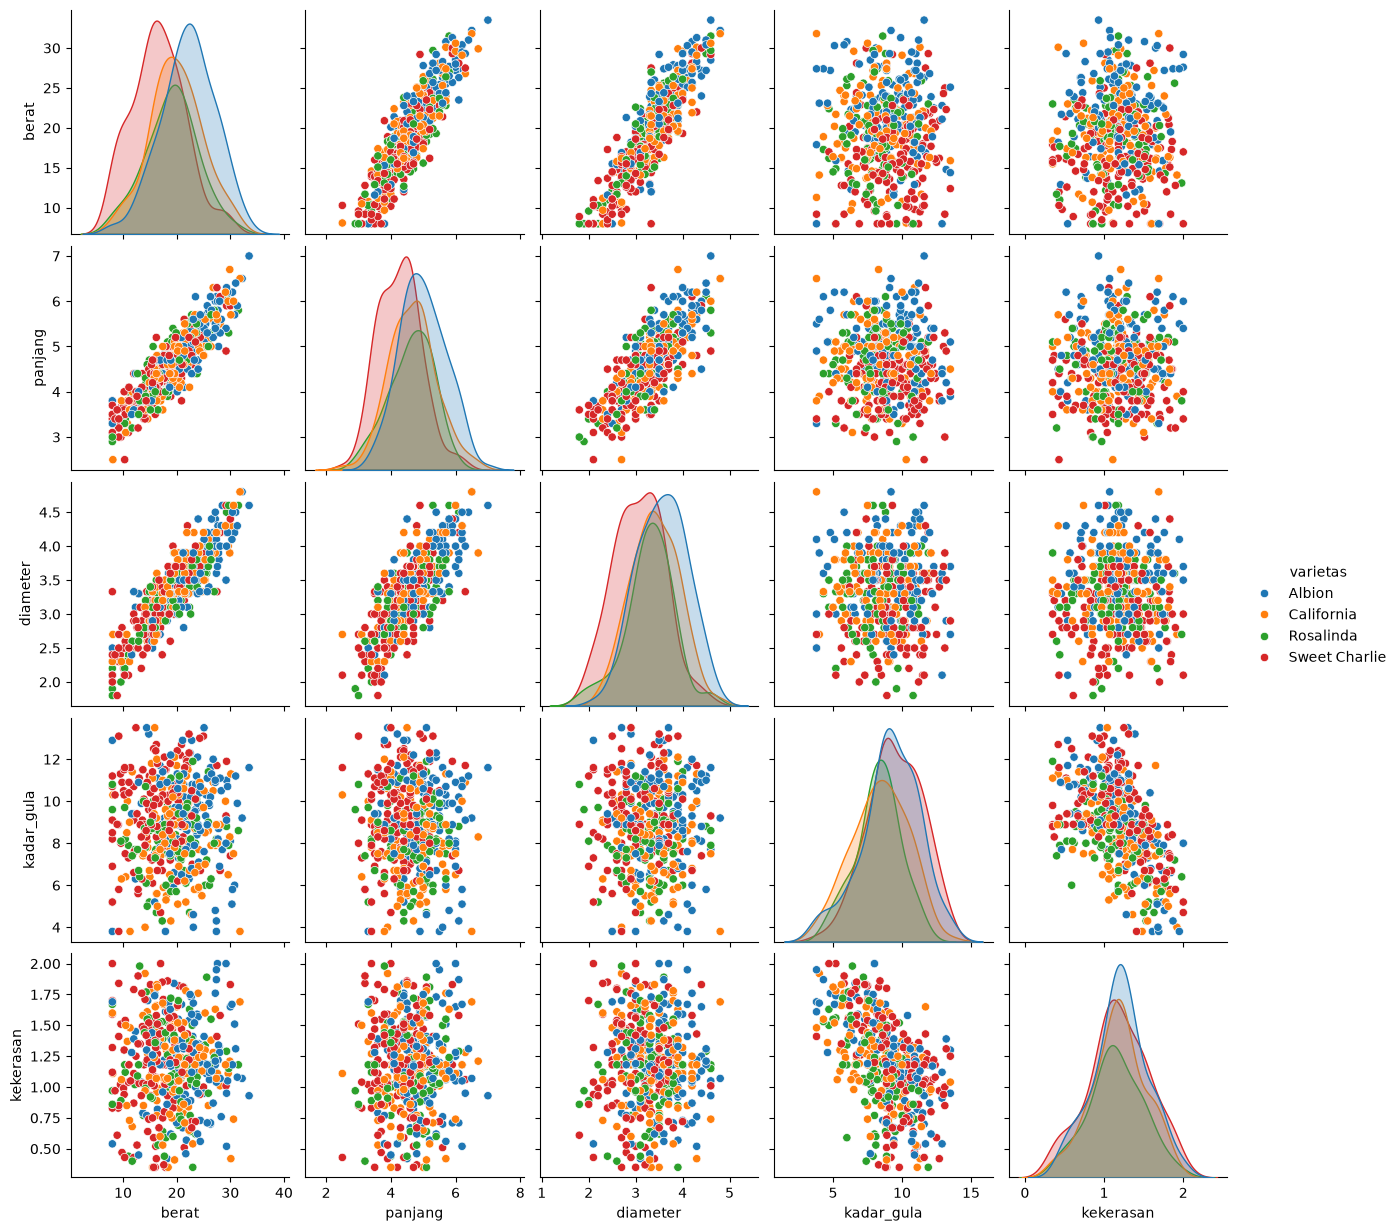

In [22]:
import seaborn as sns

sns.pairplot(df, hue="varietas")
plt.show()

In [23]:
df.to_csv("strawberry_clean.csv", index=False)

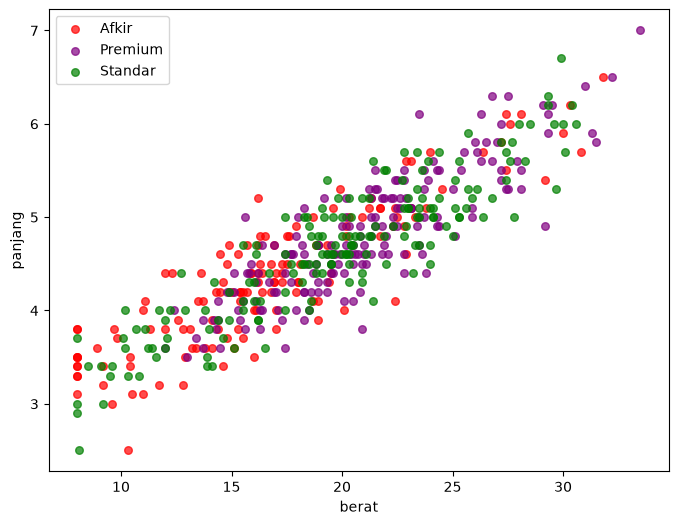

In [24]:
plt.figure(figsize=(8, 6))
warna = {"Standar": "green", "Premium": "purple", "Afkir": "red"}
for name, data in df.groupby("grade_kualitas"):
    plt.scatter(data["berat"], data["panjang"], s=30, alpha=0.7, label=name, color=warna.get(name))
plt.xlabel("berat")
plt.ylabel("panjang")
plt.legend()
plt.show()

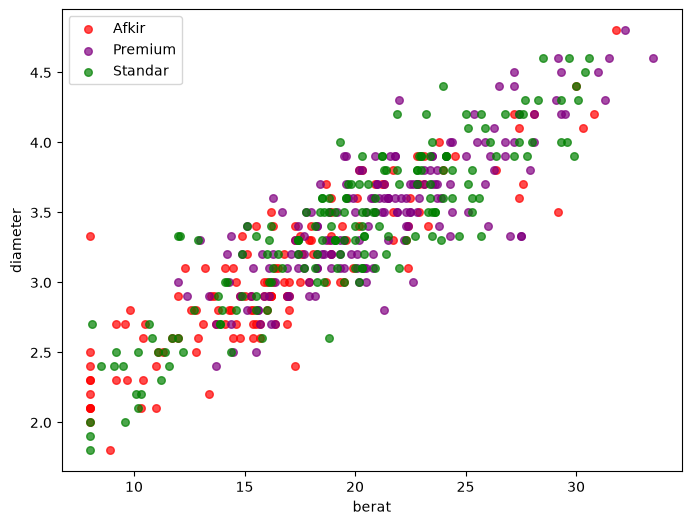

In [25]:
plt.figure(figsize=(8, 6))
warna = {"Standar": "green", "Premium": "purple", "Afkir": "red"}
for name, data in df.groupby("grade_kualitas"):
    plt.scatter(data["berat"], data["diameter"], s=30, alpha=0.7, label=name, color=warna.get(name))
plt.xlabel("berat")
plt.ylabel("diameter")
plt.legend()
plt.show()

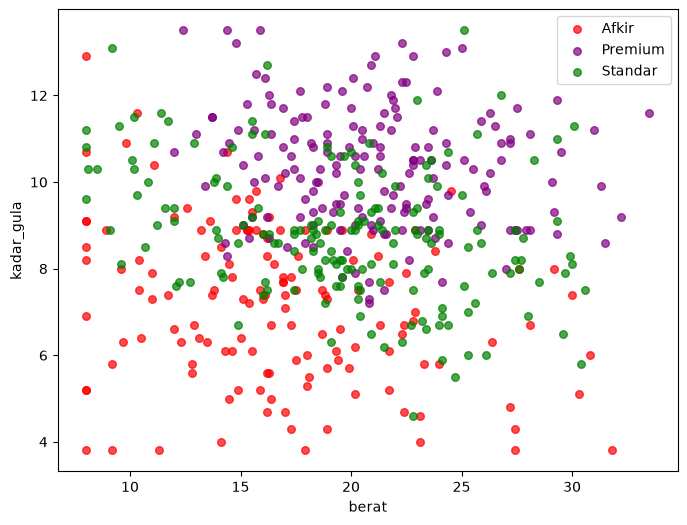

In [26]:
plt.figure(figsize=(8, 6))
warna = {"Standar": "green", "Premium": "purple", "Afkir": "red"}
for name, data in df.groupby("grade_kualitas"):
    plt.scatter(data["berat"], data["kadar_gula"], s=30, alpha=0.7, label=name, color=warna.get(name))
plt.xlabel("berat")
plt.ylabel("kadar_gula")
plt.legend()
plt.show()

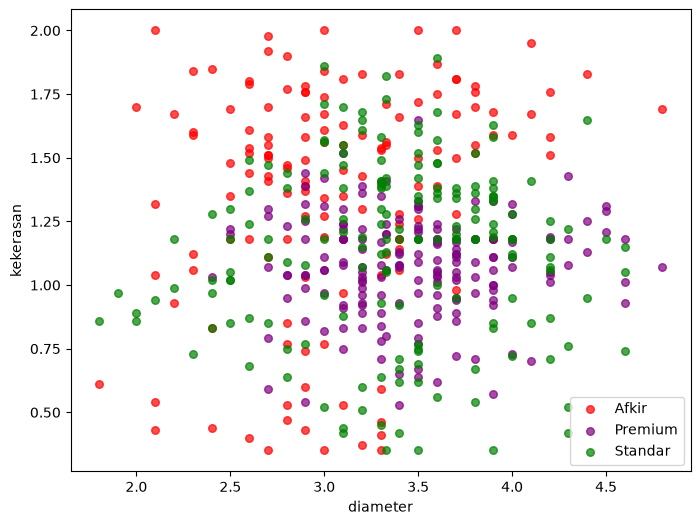

In [27]:
plt.figure(figsize=(8, 6))
warna = {"Standar": "green", "Premium": "purple", "Afkir": "red"}
for name, data in df.groupby("grade_kualitas"):
    plt.scatter(data["diameter"], data["kekerasan"], s=30, alpha=0.7, label=name, color=warna.get(name))
plt.xlabel("diameter")
plt.ylabel("kekerasan")
plt.legend()
plt.show()

In [28]:
X = df.drop(columns=["grade_kualitas"])
y = df["grade_kualitas"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = ["berat", "panjang", "diameter", "kadar_gula", "kekerasan"]
cat_cols = ["varietas", "asal_kota"]
ord_cols = ["tingkat_kematangan", "warna_kulit"]
tingkat_kematangan_order = ["Mentah", "Mengkal", "Matang", "Terlalu Matang"]
warna_kulit_order = ["Hijau Putih", "Merah Muda", "Merah", "Merah Tua"]
ord_order = [tingkat_kematangan_order, warna_kulit_order]

preprocessing = ColumnTransformer(
    transformers = [
        ("scaler", StandardScaler(), num_cols),
        ("ohe", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("ordinal", OrdinalEncoder(categories=ord_order), ord_cols)
    ], n_jobs=-1
)

model = Pipeline(
    steps = [
        ("preprocessing", preprocessing),
        ("model", RandomForestClassifier(random_state=42)),
    ]
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
scores = cross_val_score(model, X_train, y_train, cv=5)
print("Akurasi Train :", accuracy_score(y_train, model.predict(X_train)))
print("Akurasi Test  :", accuracy_score(y_test, y_pred))
print("CV Scores     :", scores)
print(f"CV Mean       : {scores.mean()} (± {scores.std():.4f})\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

model.get_params()

Akurasi Train : 1.0
Akurasi Test  : 0.9090909090909091
CV Scores     : [0.88607595 0.88607595 0.92307692 0.94871795 0.92307692]
CV Mean       : 0.9134047387211945 (± 0.0242)

Classification Report:
              precision    recall  f1-score   support

       Afkir       0.89      0.86      0.87        28
     Premium       0.97      0.97      0.97        36
     Standar       0.86      0.89      0.87        35

    accuracy                           0.91        99
   macro avg       0.91      0.91      0.91        99
weighted avg       0.91      0.91      0.91        99

Confusion Matrix:
[[24  0  4]
 [ 0 35  1]
 [ 3  1 31]]


{'memory': None,
 'steps': [('preprocessing', ColumnTransformer(n_jobs=-1,
                     transformers=[('scaler', StandardScaler(),
                                    ['berat', 'panjang', 'diameter', 'kadar_gula',
                                     'kekerasan']),
                                   ('ohe', OneHotEncoder(handle_unknown='ignore'),
                                    ['varietas', 'asal_kota']),
                                   ('ordinal',
                                    OrdinalEncoder(categories=[['Mentah',
                                                                'Mengkal',
                                                                'Matang',
                                                                'Terlalu Matang'],
                                                               ['Hijau Putih',
                                                                'Merah Muda',
                                                                'Mera

In [29]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__n_estimators" : [100, 200, 300],
    "model__max_depth" : [None, 10, 20],
    "model__min_samples_leaf" : [1, 2, 4],
    "model__criterion" : ["gini", "entropy"]
}

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)


grid.fit(X_train, y_train)

best_model = grid.best_estimator_
best_params = grid.best_params_
best_score = grid.best_score_

print("Best Parameters: ", best_params)
print("Best Score: ", best_score)

y_pred = best_model.predict(X_test)
print("Akurasi Train :", accuracy_score(y_train, model.predict(X_train)))
print("Akurasi Test  :", accuracy_score(y_test, y_pred))
print("CV Scores     :", scores)
print(f"CV Mean       : {scores.mean()} (± {scores.std():.4f})\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Best Parameters:  {'model__criterion': 'entropy', 'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best Score:  0.9159363842908148
Akurasi Train : 1.0
Akurasi Test  : 0.9090909090909091
CV Scores     : [0.88607595 0.88607595 0.92307692 0.94871795 0.92307692]
CV Mean       : 0.9134047387211945 (± 0.0242)

Classification Report:
              precision    recall  f1-score   support

       Afkir       0.89      0.86      0.87        28
     Premium       0.97      0.97      0.97        36
     Standar       0.86      0.89      0.87        35

    accuracy                           0.91        99
   macro avg       0.91      0.91      0.91        99
weighted avg       0.91      0.91      0.91        99

Confusion Matrix:
[[24  0  4]
 [ 0 35  1]
 [ 3  1 31]]


In [32]:
joblib.dump(best_model, "bestmodel.joblib")

['bestmodel.joblib']